In [15]:
import pandas as pd
import numpy as np
import sqlite3

np.random.seed(42)

# 20 synthetic (made-up) AI vendors
n = 20
vendors = pd.DataFrame({
    "vendor_id": range(1, n + 1),
    "vendor_name": [f"Vendor_{i:02d}" for i in range(1, n + 1)],
    "data_privacy": np.random.randint(1, 6, n),       # 1 = low risk, 5 = high risk
    "ai_bias": np.random.randint(1, 6, n),
    "security": np.random.randint(1, 6, n),
    "regulatory": np.random.randint(1, 6, n),
    "third_party": np.random.randint(1, 6, n),
})

# Save to SQL database (SQLite)
conn = sqlite3.connect("vendor_risk.db")
vendors.to_sql("vendors", conn, if_exists="replace", index=False)

# Check with a SQL query
print(pd.read_sql("SELECT * FROM vendors LIMIT 5", conn))

   vendor_id vendor_name  data_privacy  ai_bias  security  regulatory  \
0          1   Vendor_01             4        2         4           2   
1          2   Vendor_02             5        5         1           4   
2          3   Vendor_03             3        4         4           5   
3          4   Vendor_04             5        1         2           2   
4          5   Vendor_05             5        1         2           2   

   third_party  
0            5  
1            1  
2            5  
3            5  
4            1  


In [16]:
# Weights (total = 1.0). These are my assumptions, explain them in the README.
weights = {"data_privacy": 0.25, "security": 0.25, "regulatory": 0.20,
           "ai_bias": 0.15, "third_party": 0.15}

# Risk score out of 100
vendors["risk_score"] = sum(vendors[c] * w for c, w in weights.items()) * 20

# High / Medium / Low
vendors["risk_level"] = pd.cut(vendors["risk_score"], bins=[0, 50, 65, 100],
                               labels=["Low", "Medium", "High"]).astype(str)

# Save to SQL and check
vendors.to_sql("vendor_scores", conn, if_exists="replace", index=False)
print(pd.read_sql("SELECT risk_level, COUNT(*) AS vendors FROM vendor_scores GROUP BY risk_level", conn))
print(vendors.sort_values("risk_score", ascending=False).head())

  risk_level  vendors
0       High        8
1        Low        5
2     Medium        7
    vendor_id vendor_name  data_privacy  ai_bias  security  regulatory  \
12         13   Vendor_13             5        4         4           5   
2           3   Vendor_03             3        4         4           5   
9          10   Vendor_10             5        4         4           4   
17         18   Vendor_18             5        5         2           4   
11         12   Vendor_12             3        4         4           5   

    third_party  risk_score risk_level  
12            3        86.0       High  
2             5        82.0       High  
9             3        82.0       High  
17            2        72.0       High  
11            1        70.0       High  


In [17]:
import pandas as pd
import numpy as np
import sqlite3

np.random.seed(42)

# STEP 1: 20 synthetic (made-up) AI vendors
n = 20
vendors = pd.DataFrame({
    "vendor_id": range(1, n + 1),
    "vendor_name": [f"Vendor_{i:02d}" for i in range(1, n + 1)],
    "data_privacy": np.random.randint(1, 6, n),
    "ai_bias": np.random.randint(1, 6, n),
    "security": np.random.randint(1, 6, n),
    "regulatory": np.random.randint(1, 6, n),
    "third_party": np.random.randint(1, 6, n),
})

conn = sqlite3.connect("vendor_risk.db")
vendors.to_sql("vendors", conn, if_exists="replace", index=False)
print("STEP 1: First 5 vendors")
print(pd.read_sql("SELECT * FROM vendors LIMIT 5", conn))

# STEP 2: Risk score and classification
weights = {"data_privacy": 0.25, "security": 0.25, "regulatory": 0.20,
           "ai_bias": 0.15, "third_party": 0.15}

vendors["risk_score"] = sum(vendors[c] * w for c, w in weights.items()) * 20
vendors["risk_level"] = pd.cut(vendors["risk_score"], bins=[0, 50, 65, 100],
                               labels=["Low", "Medium", "High"]).astype(str)

vendors.to_sql("vendor_scores", conn, if_exists="replace", index=False)
print("\nSTEP 2: Vendors per risk level")
print(pd.read_sql("SELECT risk_level, COUNT(*) AS vendors FROM vendor_scores GROUP BY risk_level", conn))
print("\nTop 5 riskiest vendors")
print(vendors.sort_values("risk_score", ascending=False).head())


STEP 1: First 5 vendors
   vendor_id vendor_name  data_privacy  ai_bias  security  regulatory  \
0          1   Vendor_01             4        2         4           2   
1          2   Vendor_02             5        5         1           4   
2          3   Vendor_03             3        4         4           5   
3          4   Vendor_04             5        1         2           2   
4          5   Vendor_05             5        1         2           2   

   third_party  
0            5  
1            1  
2            5  
3            5  
4            1  

STEP 2: Vendors per risk level
  risk_level  vendors
0       High        8
1        Low        5
2     Medium        7

Top 5 riskiest vendors
    vendor_id vendor_name  data_privacy  ai_bias  security  regulatory  \
12         13   Vendor_13             5        4         4           5   
2           3   Vendor_03             3        4         4           5   
9          10   Vendor_10             5        4         4           

In [18]:
from google.colab import files

risk_cols = ["data_privacy", "ai_bias", "security", "regulatory", "third_party"]

# Biggest risk area for each vendor
vendors["top_risk_area"] = vendors[risk_cols].idxmax(axis=1)

# Recommendation for each risk area (my assumptions, explain in README)
recommendations = {
    "data_privacy": "Review the data processing agreement. Check consent, retention and data-sharing controls.",
    "ai_bias": "Request bias testing results and model documentation. Add human review for high-impact decisions.",
    "security": "Request security audit reports. Review access controls and incident response plan.",
    "regulatory": "Map the vendor to applicable regulations. Request written compliance confirmations.",
    "third_party": "Review the vendor's sub-processors. Add audit-rights and exit-plan clauses to the contract.",
}
vendors["recommendation"] = vendors["top_risk_area"].map(recommendations)

# Action priority by risk level
priority = {"High": "Immediate review", "Medium": "Review this quarter", "Low": "Routine monitoring"}
vendors["action_priority"] = vendors["risk_level"].map(priority)

# Final Risk Register
register = vendors[["vendor_id", "vendor_name", "risk_score", "risk_level",
                    "top_risk_area", "recommendation", "action_priority"]] \
    .sort_values("risk_score", ascending=False)

register.to_sql("risk_register", conn, if_exists="replace", index=False)
print(register.head(8).to_string(index=False))

# Save CSV files for Power BI
register.to_csv("risk_register.csv", index=False)
vendors.to_csv("vendor_scores.csv", index=False)
files.download("risk_register.csv")
files.download("vendor_scores.csv")

 vendor_id vendor_name  risk_score risk_level top_risk_area                                                                              recommendation  action_priority
        13   Vendor_13        86.0       High  data_privacy   Review the data processing agreement. Check consent, retention and data-sharing controls. Immediate review
         3   Vendor_03        82.0       High    regulatory         Map the vendor to applicable regulations. Request written compliance confirmations. Immediate review
        10   Vendor_10        82.0       High  data_privacy   Review the data processing agreement. Check consent, retention and data-sharing controls. Immediate review
        18   Vendor_18        72.0       High  data_privacy   Review the data processing agreement. Check consent, retention and data-sharing controls. Immediate review
        12   Vendor_12        70.0       High    regulatory         Map the vendor to applicable regulations. Request written compliance confirmations. Imm

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

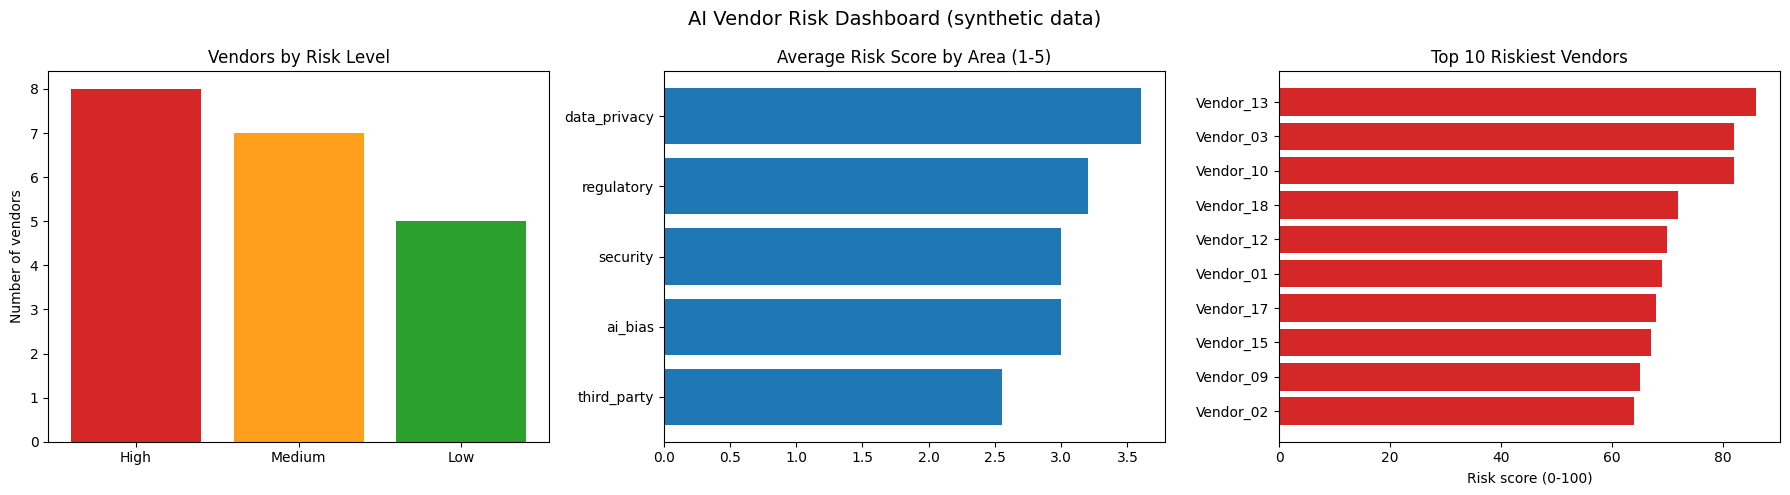

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Vendors per risk level
order = ["High", "Medium", "Low"]
counts = vendors["risk_level"].value_counts().reindex(order)
axes[0].bar(order, counts.values, color=["#d62728", "#ff9f1c", "#2ca02c"])
axes[0].set_title("Vendors by Risk Level")
axes[0].set_ylabel("Number of vendors")

# 2. Average risk by area
avg = vendors[risk_cols].mean().sort_values()
axes[1].barh(avg.index, avg.values, color="#1f77b4")
axes[1].set_title("Average Risk Score by Area (1-5)")

# 3. Top 10 riskiest vendors
top = vendors.sort_values("risk_score", ascending=False).head(10)
axes[2].barh(top["vendor_name"], top["risk_score"], color="#d62728")
axes[2].invert_yaxis()
axes[2].set_title("Top 10 Riskiest Vendors")
axes[2].set_xlabel("Risk score (0-100)")

plt.suptitle("AI Vendor Risk Dashboard (synthetic data)", fontsize=14)
plt.tight_layout()
plt.savefig("dashboard.png", dpi=150)
plt.show()
files.download("dashboard.png")